# Can the original row model be replaced? RF, LightGBM, and best_model ideas

`dose_trajectory_walkthrough.ipynb` blends an **original row ensemble** (cosine centroid + cosine 7-NN + logistic regression on rows ≥ 0.37 µM, averaged per compound) with a dose-trajectory model. This notebook only asks whether a different model in the **original** slot does better.

**Held fixed (copied verbatim from the walkthrough):** plate-median centering, the 782 low-batch genes, the row filter (≥ 0.37 µM plus the downweighted control), balanced row weights, per-compound probability averaging, compound-stratified 5-fold CV, and the trajectory model itself.

**What changes:** only the classifier in the original slot. The candidates are:

| candidate | idea |
|---|---|
| `rf` | random forest, 500 trees, `max_features="sqrt"`, default leaves |
| `rf_leafN` | the same forest with `min_samples_leaf=N`; N is chosen on seeds 10–19 only |
| `extratrees` | extremely randomized trees, 500 trees |
| `lightgbm` | LightGBM with the tuned parameters from `best_model.ipynb` |
| `lightgbm_alldoses` | the same, but trained on and averaged over all six doses, as in `best_model.ipynb` |
| `A+B` | equal-weight probability average of two slot models |
| `(1-w)·original + w·rf_leafN` | weighted average of the original and RF probabilities; N and w are chosen on seeds 10–19 only (§5) |
| `+evidence` | `best_model.ipynb` PARP (p53 module + amplitude) and RAF (ERK paradoxical-activation) logistic evidence terms, mixed in at w = 0.1 and 0.3 |
| `[prior]` | `best_model.ipynb` decision rule: P / prior^α, with α picked on the other folds only (nested) |

**Validation:** 20 seeds (10–29) × 5 compound-stratified folds. Every candidate sees exactly the same splits, so comparisons are paired by seed. Anything tuned here (RF leaf size, mixing weight) is chosen on **seeds 10–19** only. **Seeds 20–29** are reported separately as fresh seeds. They re-split the same 86 compounds, so this is a guard against picking a lucky setting, not an independent test set. The trajectory and blend confusion matrices are **not** redrawn. The last table only reports what the 25/75 blend *would* score if the slot model were swapped.

## 1. Settings

In [1]:
from pathlib import Path
import os, warnings, time

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import lightgbm as lgb
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.decomposition import PCA
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "X_train.csv.gz").exists():
    ROOT = ROOT.parent
RESULTS = ROOT / "results" / "original_model_alternatives"
PLOTS = ROOT / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)

TRAIN_CONTROL = "BRD-K60230970"
UNLABELED_CONTROL = "BRD-K50691590"
DOSES = np.array([0.04, 0.12, 0.37, 1.11, 3.33, 10.0])
LOG_DOSES = np.log10(DOSES)
SEEDS = list(range(10, 30))          # 20 repeats: the walkthrough's 10-14 and 20-24, plus 15-19 and 25-29
TUNE_SEEDS, FRESH_SEEDS = SEEDS[:10], SEEDS[10:]   # tuning choices use 10-19 only; 20-29 are reported as fresh
FOLDS = 5
N_COMPONENTS = 64
TRAJECTORY_WEIGHT = 0.75
N_JOBS = min(len(SEEDS), os.cpu_count() or 1)

## 2. Data, preprocessing, and trajectory features (verbatim from the walkthrough)

In [2]:
classes = [line.strip() for line in (ROOT / "classes.txt").read_text().splitlines() if line.strip()]
train = pd.read_csv(ROOT / "X_train.csv.gz", index_col=0)
test = pd.read_csv(ROOT / "X_test.csv.gz", index_col=0)
unlabeled_full = pd.read_csv(ROOT / "X_unlabeled.csv.gz", index_col=0)
meta_train = pd.read_csv(ROOT / "meta_train.csv", index_col=0).loc[train.index]
meta_test = pd.read_csv(ROOT / "meta_test.csv", index_col=0).loc[test.index]
meta_unlabeled = unlabeled_full[["compound", "dose_um"]]
unlabeled = unlabeled_full.drop(columns=["compound", "dose_um"])
row_labels = pd.read_csv(ROOT / "y_train.csv", index_col=0)["moa"].loc[train.index]

train_control = meta_train["compound"].eq(TRAIN_CONTROL).to_numpy()
unlabeled_control = meta_unlabeled["compound"].eq(UNLABELED_CONTROL).to_numpy()

print("train expression:", train.shape)
print("test expression:", test.shape)
print("unlabeled expression:", unlabeled.shape)
print("real labeled compounds:", meta_train.loc[~train_control, "compound"].nunique())
print("test compounds:", meta_test["compound"].nunique())

train expression: (815, 978)
test expression: (174, 978)
unlabeled expression: (7993, 978)
real labeled compounds: 86
test compounds: 29


In [3]:
def plate_ids(index):
    return index.str.split(":").str[0].to_numpy()


def plate_center(train, test, unlabeled, train_control, unlabeled_control):
    p_train, p_test, p_unlabeled = map(plate_ids, [train.index, test.index, unlabeled.index])
    values = np.vstack([
        unlabeled.to_numpy(float)[~unlabeled_control],
        train.to_numpy(float)[~train_control],
        test.to_numpy(float),
    ])
    plates = np.concatenate([
        p_unlabeled[~unlabeled_control],
        p_train[~train_control],
        p_test,
    ])
    medians = {plate: np.median(values[plates == plate], axis=0) for plate in np.unique(plates)}

    def apply(frame, frame_plates):
        return frame.to_numpy(float) - np.vstack([medians[p] for p in frame_plates])

    return apply(train, p_train), apply(test, p_test), apply(unlabeled, p_unlabeled)


def select_low_batch_genes(unlabeled, control):
    values = unlabeled.to_numpy(float)[~control]
    plates = plate_ids(unlabeled.index)[~control]
    grand = values.mean(axis=0)
    total = np.square(values - grand).sum(axis=0)
    between = np.zeros(values.shape[1])
    for plate in np.unique(plates):
        rows = values[plates == plate]
        between += len(rows) * np.square(rows.mean(axis=0) - grand)
    r2 = np.divide(between, total, out=np.ones_like(between), where=total > 0)
    return np.flatnonzero(r2 <= np.quantile(r2, 0.80)), r2


x_train, x_test, x_unlabeled = plate_center(
    train, test, unlabeled, train_control, unlabeled_control
)
genes, plate_r2 = select_low_batch_genes(unlabeled, unlabeled_control)
print(f"Selected {len(genes)} of {train.shape[1]} genes")
print(f"Plate-R² cutoff: {np.quantile(plate_r2, 0.80):.4f}")

Selected 782 of 978 genes
Plate-R² cutoff: 0.0693


In [4]:
gene_scaler = StandardScaler()
unlabeled_scaled = gene_scaler.fit_transform(x_unlabeled[~unlabeled_control][:, genes])
pca = PCA(n_components=N_COMPONENTS, svd_solver="randomized", random_state=2026)
pca.fit(unlabeled_scaled)

train_module_scores = pca.transform(gene_scaler.transform(x_train[:, genes]))
test_module_scores = pca.transform(gene_scaler.transform(x_test[:, genes]))

print("Module-score matrix for train rows:", train_module_scores.shape)
print(f"Variance explained by {N_COMPONENTS} modules: {pca.explained_variance_ratio_.sum():.1%}")

Module-score matrix for train rows: (815, 64)
Variance explained by 64 modules: 47.1%


In [5]:
def interpolate_trajectory(values, observed_doses):
    order = np.argsort(observed_doses)
    observed_log = np.log10(observed_doses[order])
    observed_values = values[order]
    result = np.empty((len(DOSES), values.shape[1]))
    for module in range(values.shape[1]):
        result[:, module] = np.interp(
            LOG_DOSES, observed_log, observed_values[:, module]
        )
    return result


def trajectory_summary(trajectory):
    peak_position = np.abs(trajectory).argmax(axis=0)
    signed_peak = trajectory[peak_position, np.arange(trajectory.shape[1])]
    auc = np.trapezoid(trajectory, LOG_DOSES, axis=0) / (LOG_DOSES[-1] - LOG_DOSES[0])
    centered_dose = LOG_DOSES - LOG_DOSES.mean()
    slope = (centered_dose[:, None] * trajectory).sum(axis=0) / np.square(centered_dose).sum()
    reaches_half = np.abs(trajectory) >= (0.5 * np.abs(signed_peak))[None, :]
    onset_position = reaches_half.argmax(axis=0)
    onset = (LOG_DOSES[onset_position] - LOG_DOSES[0]) / (LOG_DOSES[-1] - LOG_DOSES[0])
    saturation = trajectory[-1] - trajectory[-2]
    reversal = trajectory[-1] - signed_peak
    return np.concatenate([signed_peak, auc, slope, onset, saturation, reversal])


def make_compound_features(row_scores, metadata, exclude_control=None):
    compound_values = metadata["compound"].to_numpy()
    dose_values = metadata["dose_um"].to_numpy(float)
    names = sorted(set(compound_values) - ({exclude_control} if exclude_control else set()))
    features = []
    for compound in names:
        selected = compound_values == compound
        trajectory = interpolate_trajectory(row_scores[selected], dose_values[selected])
        raw_levels = trajectory.T.reshape(-1)  # six adjacent doses for each module
        features.append(np.concatenate([raw_levels, trajectory_summary(trajectory)]))
    return pd.DataFrame(features, index=pd.Index(names, name="compound"))


trajectory_train = make_compound_features(
    train_module_scores, meta_train, exclude_control=TRAIN_CONTROL
)
trajectory_test = make_compound_features(test_module_scores, meta_test)
print("Labeled compound trajectory matrix:", trajectory_train.shape)
print("Test compound trajectory matrix:", trajectory_test.shape)

Labeled compound trajectory matrix: (86, 768)
Test compound trajectory matrix: (29, 768)


## 3. Model definitions

The walkthrough's model functions, copied unchanged:

In [6]:
def unit(values):
    return values / (np.linalg.norm(values, axis=1, keepdims=True) + 1e-9)


def softmax(scores, temperature=0.1):
    shifted = (scores - scores.max(axis=1, keepdims=True)) / temperature
    exponent = np.exp(shifted)
    return exponent / exponent.sum(axis=1, keepdims=True)


def balanced_row_weights(labels, controls, real_rows, real_compounds):
    control_factor = real_rows / real_compounds / controls.sum()
    weights = np.where(controls, control_factor, 1.0).astype(float)
    for label in np.unique(labels):
        selected = labels == label
        weights[selected] /= weights[selected].sum()
    return weights * len(weights) / weights.sum()


def balanced_compound_weights(labels):
    weights = np.ones(len(labels))
    for label in np.unique(labels):
        selected = labels == label
        weights[selected] /= selected.sum()
    return weights * len(weights) / weights.sum()


def centroid_probability(x_fit, labels, weights, x_predict, class_names):
    normalized = unit(x_fit)
    centroids = unit(np.vstack([
        np.average(normalized[labels == label], axis=0, weights=weights[labels == label])
        for label in class_names
    ]))
    return softmax(unit(x_predict) @ centroids.T, temperature=0.1)


def knn_probability(x_fit, labels, weights, x_predict, class_names, k=7):
    similarity = unit(x_predict) @ unit(x_fit).T
    neighbors = np.argsort(-similarity, axis=1)[:, :k]
    class_position = {label: index for index, label in enumerate(class_names)}
    encoded = np.array([class_position[label] for label in labels])
    probability = np.zeros((len(x_predict), len(class_names)))
    for row in range(len(x_predict)):
        index = neighbors[row]
        neighbor_weight = np.exp(similarity[row, index] / 0.1) * weights[index]
        np.add.at(probability[row], encoded[index], neighbor_weight)
    return probability / probability.sum(axis=1, keepdims=True)


def logistic_probability(x_fit, labels, weights, x_predict, class_names):
    scaler = StandardScaler()
    fit_scaled = scaler.fit_transform(x_fit)
    predict_scaled = scaler.transform(x_predict)
    model = LogisticRegression(C=0.05, max_iter=3000, random_state=2026)
    model.fit(fit_scaled, labels, sample_weight=weights)
    probability = pd.DataFrame(model.predict_proba(predict_scaled), columns=model.classes_)
    return probability.reindex(columns=class_names, fill_value=0.0).to_numpy()


def row_ensemble_probability(x_fit, labels, weights, x_predict, class_names):
    return (
        centroid_probability(x_fit, labels, weights, x_predict, class_names)
        + knn_probability(x_fit, labels, weights, x_predict, class_names)
        + logistic_probability(x_fit, labels, weights, x_predict, class_names)
    ) / 3.0


def trajectory_model_probability(name, x_fit, labels, weights, x_predict, class_names):
    scaler = StandardScaler()
    fit_scaled = scaler.fit_transform(x_fit)
    predict_scaled = scaler.transform(x_predict)
    if name == "centroid":
        return centroid_probability(fit_scaled, labels, weights, predict_scaled, class_names)
    if name == "knn":
        return knn_probability(fit_scaled, labels, weights, predict_scaled, class_names)
    if name == "logreg":
        model = LogisticRegression(C=0.05, max_iter=3000, random_state=2026)
        model.fit(fit_scaled, labels, sample_weight=weights)
        probability = pd.DataFrame(model.predict_proba(predict_scaled), columns=model.classes_)
        return probability.reindex(columns=class_names, fill_value=0.0).to_numpy()
    raise ValueError(name)


def trajectory_ensemble_probability(x_fit, labels, weights, x_predict, class_names):
    return np.mean([
        trajectory_model_probability(name, x_fit, labels, weights, x_predict, class_names)
        for name in ["centroid", "knn", "logreg"]
    ], axis=0)


def aggregate_rows(probability, row_index, metadata, class_names):
    frame = pd.DataFrame(probability, index=row_index, columns=class_names)
    result = frame.groupby(metadata.loc[row_index, "compound"]).mean()
    result = result.reindex(columns=class_names)
    result = result.div(result.sum(axis=1), axis=0)
    result.index.name = "compound"
    return result

Replacement candidates for the original slot. Every candidate gets the same inputs: the plate-centered values for the 782 selected genes, and the same balanced row weights passed as `sample_weight`. Tree models are insensitive to feature scaling, so no scaler is applied.

In [7]:
# Tuned LightGBM parameters from best_model.ipynb (class_weight is replaced by the walkthrough's balanced row weights)
LGB_PARAMS = dict(n_estimators=456, num_leaves=5, max_depth=3, learning_rate=0.085, min_child_samples=5,
                  subsample=0.82, subsample_freq=1, colsample_bytree=0.24, reg_lambda=7.69, verbose=-1, n_jobs=1)


def _sklearn_probability(model, x_fit, labels, weights, x_predict, class_names):
    model.fit(x_fit, labels, sample_weight=weights)
    probability = pd.DataFrame(model.predict_proba(x_predict), columns=model.classes_)
    return probability.reindex(columns=class_names, fill_value=0.0).to_numpy()


def rf_probability(x_fit, labels, weights, x_predict, class_names, min_samples_leaf=1):
    model = RandomForestClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=min_samples_leaf,
                                   n_jobs=1, random_state=2026)
    return _sklearn_probability(model, x_fit, labels, weights, x_predict, class_names)


def extratrees_probability(x_fit, labels, weights, x_predict, class_names):
    model = ExtraTreesClassifier(n_estimators=500, max_features="sqrt", n_jobs=1, random_state=2026)
    return _sklearn_probability(model, x_fit, labels, weights, x_predict, class_names)


def lightgbm_probability(x_fit, labels, weights, x_predict, class_names):
    model = lgb.LGBMClassifier(**LGB_PARAMS, random_state=2026)
    return _sklearn_probability(model, x_fit, labels, weights, x_predict, class_names)


RF_LEAVES = [1, 3, 5, 8, 12, 16, 24]
SLOT_MODELS = {"original": row_ensemble_probability}
for leaf in RF_LEAVES:
    SLOT_MODELS["rf" if leaf == 1 else f"rf_leaf{leaf}"] = (
        lambda xf, lab, w, xp, cn, leaf=leaf: rf_probability(xf, lab, w, xp, cn, min_samples_leaf=leaf))
SLOT_MODELS["extratrees"] = extratrees_probability
SLOT_MODELS["lightgbm"] = lightgbm_probability

### best_model.ipynb evidence terms

Two label-free compound features, computed exactly as in `best_model.ipynb` (genes calibrated by the median/MAD of unlabeled 3.33 + 10 µM profiles):

- **RAF:** ERK-output score (DUSP6, DUSP4, IER3, ETV1, FOSL1, SPRED2). The index is high when ERK output peaks at a low dose and falls at 10 µM (paradoxical activation).
- **PARP:** p53-module score (CDKN1A, DDB2, FAS, SESN1, BAX, GADD45A) plus the log of the transcriptional amplitude.

Inside each fold, a one-vs-rest logistic regression on the training compounds turns each feature into a class probability. That probability is mixed into the slot model's PARP column (w = 0.1) and RAF column (w = 0.3).

In [8]:
ERK = ["208891_at", "204014_at", "201631_s_at", "206501_x_at", "204420_at", "212458_at"]
P53 = ["202284_s_at", "203409_at", "204781_s_at", "218346_s_at", "208478_s_at", "203725_at"]
gene_names = list(train.columns)
gene_index = lambda probes: [gene_names.index(p) for p in probes]

unlabeled_profiles = unlabeled_full[unlabeled_full["compound"].ne(TRAIN_CONTROL) & unlabeled_full["dose_um"].isin([3.33, 10.0])]
unlabeled_profiles = unlabeled_profiles.groupby("compound")[gene_names].mean()
MED = unlabeled_profiles.median().to_numpy()
MAD = (unlabeled_profiles - MED).abs().median().to_numpy() * 1.4826
MAD[MAD < 1e-6] = 1

real_rows = ~train_control
calibrated = (train.to_numpy(float)[real_rows] - MED) / MAD
row_compound = meta_train["compound"].to_numpy()[real_rows]
row_dose = meta_train["dose_um"].to_numpy(float)[real_rows]

erk = (pd.DataFrame({"c": row_compound, "d": row_dose, "v": calibrated[:, gene_index(ERK)].mean(1)})
       .pivot_table(index="c", columns="d", values="v").T.interpolate(limit_direction="both").T)
erk_peak = erk[list(DOSES[:4])].max(1)
RAF_FEATURES = pd.DataFrame({"raf_index": np.minimum(erk_peak, erk_peak - erk[10.0])})

top_dose = np.isin(row_dose, [3.33, 10.0])
p53 = pd.Series(calibrated[top_dose][:, gene_index(P53)].mean(1), index=row_compound[top_dose]).groupby(level=0).mean()
amplitude = pd.Series((np.abs(calibrated) > 2).sum(1), index=row_compound).groupby(level=0).max()
PARP_FEATURES = pd.DataFrame({"p53": p53, "log_amplitude": np.log10(amplitude + 1)})


def add_evidence(probability, fit_compounds, fit_labels, predict_compounds):
    probability = probability.copy()
    for label, weight, features in [("PARP inhibitor", 0.1, PARP_FEATURES), ("RAF inhibitor", 0.3, RAF_FEATURES)]:
        model = LogisticRegression(max_iter=1000, class_weight="balanced")
        model.fit(features.loc[fit_compounds].to_numpy(), fit_labels == label)
        column = classes.index(label)
        probability[:, column] = ((1 - weight) * probability[:, column]
                                  + weight * model.predict_proba(features.loc[predict_compounds].to_numpy())[:, 1])
    return probability / probability.sum(axis=1, keepdims=True)

## 4. Compound-grouped cross-validation, 20 seeds

The fold construction, row filter, and weights are the same as in the walkthrough's CV cell. One seed runs per worker. The trajectory model is fitted on the same folds so the blend can be scored afterwards.

In [9]:
compounds = meta_train["compound"].to_numpy()
doses = meta_train["dose_um"].to_numpy(float)
label_values = row_labels.to_numpy()
compound_truth = pd.Series(
    label_values[~train_control], index=compounds[~train_control]
).groupby(level=0).first()
compound_names = compound_truth.index.to_numpy()
compound_labels = compound_truth.to_numpy()
trajectory_train = trajectory_train.loc[compound_names]
trajectory_values = trajectory_train.to_numpy()


def run_seed(seed):
    records = []
    splitter = StratifiedKFold(FOLDS, shuffle=True, random_state=seed)
    for fold, (fit_position, validation_position) in enumerate(splitter.split(compound_names, compound_labels)):
        is_validation = np.isin(compounds, compound_names[validation_position])
        common = dict(real_rows=int((~train_control).sum()), real_compounds=len(compound_truth))

        # Original slot: identical rows and weights for every candidate
        fit_rows = (~is_validation) & ((doses >= 0.37) | train_control)
        validation_rows = is_validation & (~train_control) & (doses >= 0.37)
        fit_labels = label_values[fit_rows]
        row_weights = balanced_row_weights(fit_labels, train_control[fit_rows], **common)
        probabilities = {
            name: aggregate_rows(fn(x_train[fit_rows][:, genes], fit_labels, row_weights,
                                    x_train[validation_rows][:, genes], classes),
                                 meta_train.index[validation_rows], meta_train, classes)
            for name, fn in SLOT_MODELS.items()
        }
        order = probabilities["original"].index

        # best_model.ipynb variant: LightGBM on every dose
        fit_all = ~is_validation
        validation_all = is_validation & (~train_control)
        all_labels = label_values[fit_all]
        all_weights = balanced_row_weights(all_labels, train_control[fit_all], **common)
        probabilities["lightgbm_alldoses"] = aggregate_rows(
            lightgbm_probability(x_train[fit_all][:, genes], all_labels, all_weights,
                                 x_train[validation_all][:, genes], classes),
            meta_train.index[validation_all], meta_train, classes).loc[order]

        # Unchanged trajectory model, only used to score the downstream blend
        trajectory_fit_labels = compound_labels[fit_position]
        probabilities["trajectory"] = pd.DataFrame(
            trajectory_ensemble_probability(trajectory_values[fit_position], trajectory_fit_labels,
                                            balanced_compound_weights(trajectory_fit_labels),
                                            trajectory_values[validation_position], classes),
            index=pd.Index(compound_names[validation_position], name="compound"), columns=classes,
        ).loc[order]

        for name, probability in probabilities.items():
            output = probability.copy()
            output["true"] = compound_truth.loc[output.index].to_numpy()
            output["model"], output["seed"], output["fold"] = name, seed, fold
            records.append(output.reset_index())
    return pd.concat(records, ignore_index=True)


start = time.time()
oof = pd.concat(Parallel(n_jobs=N_JOBS)(delayed(run_seed)(seed) for seed in SEEDS), ignore_index=True)
oof.to_pickle(RESULTS / "oof_base_models.pkl")
print(f"{len(SEEDS)} seeds x {FOLDS} folds in {time.time() - start:.0f} s; OOF rows: {len(oof)}")

/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:81

20 seeds x 5 folds in 328 s; OOF rows: 20640


## 5. Derived candidates: RF leaf size and original + RF mixing weight, evidence terms, prior correction

These are post-processing steps on the out-of-fold probabilities. Each step uses only the training compounds of the same seed and fold: the evidence-term logistic regressions are fitted on them, and the prior-correction α is chosen on the other folds' out-of-fold predictions.

chosen on seeds 10-19 -> RF alone: min_samples_leaf=12;  mix: leaf=24, rf weight=0.8


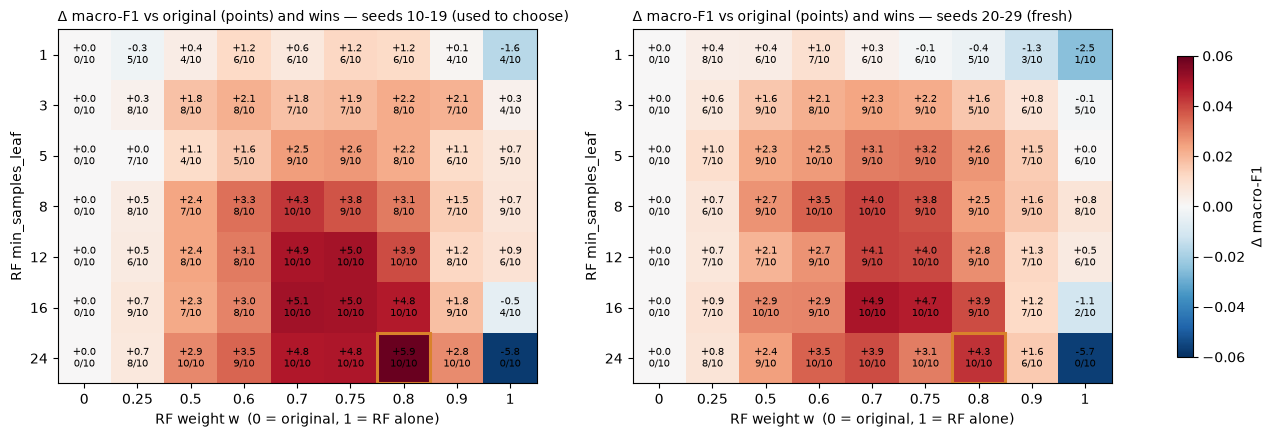

17 candidates for the original slot


In [10]:
class_array = np.asarray(classes)
by_model = {name: frame.set_index(["seed", "compound"]).sort_index() for name, frame in oof.groupby("model")}
fold_info = by_model["original"][["true", "fold"]]
base = {name: frame[classes] for name, frame in by_model.items()}
compound_prior = compound_truth.value_counts(normalize=True).reindex(classes).to_numpy()
ALPHAS = [0, 0.25, 0.5, 0.75, 1.0, 1.25]                     # grid from best_model.ipynb


def mix(*names):
    return sum(base[name] for name in names) / len(names)


def with_evidence(probability):
    parts = {}
    for seed in SEEDS:
        info, frame = fold_info.loc[seed], probability.loc[seed].copy()
        for fold in range(FOLDS):
            query, fit = info.index[info["fold"] == fold], info.index[info["fold"] != fold]
            frame.loc[query] = add_evidence(frame.loc[query].to_numpy(), fit, info.loc[fit, "true"].to_numpy(), query)
        parts[seed] = frame
    return pd.concat(parts, names=["seed"])


def prior_corrected(probability):
    parts = {}
    for seed in SEEDS:
        info, frame = fold_info.loc[seed], probability.loc[seed].copy()
        values = frame.to_numpy()
        for fold in range(FOLDS):
            fit, query = (info["fold"] != fold).to_numpy(), (info["fold"] == fold).to_numpy()
            score = lambda a: f1_score(info["true"][fit], class_array[(values[fit] / compound_prior ** a).argmax(1)],
                                       labels=classes, average="macro", zero_division=0)
            alpha = max(ALPHAS, key=score)
            adjusted = values[query] / compound_prior ** alpha
            frame.iloc[np.flatnonzero(query)] = adjusted / adjusted.sum(axis=1, keepdims=True)
        parts[seed] = frame
    return pd.concat(parts, names=["seed"])


def seed_macro_f1(probability):
    return pd.Series({seed: f1_score(fold_info.loc[seed, "true"], class_array[probability.loc[seed].to_numpy().argmax(1)],
                                     labels=classes, average="macro", zero_division=0) for seed in SEEDS})


# Grid: (1 - w) * original + w * rf_leafN.  w = 0 is the original, w = 1 is the RF alone.
RF_WEIGHTS = [0, 0.25, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9, 1.0]
rf_name = lambda leaf: "rf" if leaf == 1 else f"rf_leaf{leaf}"
grid = pd.DataFrame({(leaf, w): seed_macro_f1((1 - w) * base["original"] + w * base[rf_name(leaf)])
                     for leaf in RF_LEAVES for w in RF_WEIGHTS})
grid.columns.names = ["leaf", "rf_weight"]
grid.to_csv(RESULTS / "original_rf_mix_grid_per_seed.csv")

tune_mean = grid.loc[TUNE_SEEDS].mean()
RF_LEAF = int(tune_mean.xs(1.0, level="rf_weight").idxmax())                       # best RF alone
MIX_LEAF, MIX_W = tune_mean[tune_mean.index.get_level_values("rf_weight").map(lambda w: 0 < w < 1)].idxmax()
MIX_LEAF = int(MIX_LEAF)
RF_TUNED = rf_name(RF_LEAF)
MIX = f"{1 - MIX_W:.2f}·original + {MIX_W:.2f}·{rf_name(MIX_LEAF)}"
print(f"chosen on seeds 10-19 -> RF alone: min_samples_leaf={RF_LEAF};  mix: leaf={MIX_LEAF}, rf weight={MIX_W}")

original_f1 = grid[(1, 0)]
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6))
for ax, seeds, title in [(axes[0], TUNE_SEEDS, "seeds 10-19 (used to choose)"), (axes[1], FRESH_SEEDS, "seeds 20-29 (fresh)")]:
    d = grid.loc[seeds].sub(original_f1.loc[seeds], axis=0).mean().unstack("rf_weight")
    wins = (grid.loc[seeds].sub(original_f1.loc[seeds], axis=0) > 1e-9).sum().unstack("rf_weight")
    im = ax.imshow(d.to_numpy(), cmap="RdBu_r", vmin=-0.06, vmax=0.06, aspect="auto")
    for (i, j), v in np.ndenumerate(d.to_numpy()):
        ax.text(j, i, f"{v * 100:+.1f}\n{wins.iat[i, j]}/10", ha="center", va="center", fontsize=7)
    i, j = list(d.index).index(MIX_LEAF), list(d.columns).index(MIX_W)
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="#d9822b", linewidth=2.2))
    ax.set_xticks(range(len(d.columns)), [f"{w:g}" for w in d.columns]); ax.set_yticks(range(len(d.index)), d.index)
    ax.set_xlabel("RF weight w  (0 = original, 1 = RF alone)"); ax.set_ylabel("RF min_samples_leaf")
    ax.set_title(f"Δ macro-F1 vs original (points) and wins — {title}", loc="left", fontsize=10)
fig.colorbar(im, ax=axes, label="Δ macro-F1", shrink=0.85)
fig.savefig(PLOTS / "original_model_alternatives_rf_mix_grid.png", dpi=120, bbox_inches="tight")
plt.show()

candidates = {name: base[name] for name in ["original", "rf", "extratrees", "lightgbm", "lightgbm_alldoses"]}
candidates[RF_TUNED] = base[RF_TUNED]
candidates[MIX] = (1 - MIX_W) * base["original"] + MIX_W * base[rf_name(MIX_LEAF)]
candidates[f"original+{RF_TUNED}"] = mix("original", RF_TUNED)
candidates["original+lightgbm"] = mix("original", "lightgbm")
candidates["original+evidence"] = with_evidence(candidates["original"])
candidates[f"{MIX} +evidence"] = with_evidence(candidates[MIX])
candidates["original+lightgbm+evidence"] = with_evidence(candidates["original+lightgbm"])
for name in ["original", RF_TUNED, MIX, "original+lightgbm", "original+lightgbm+evidence"]:
    candidates[f"{name} [prior]"] = prior_corrected(candidates[name])
print(len(candidates), "candidates for the original slot")

## 6. Macro-F1 over 20 seeds, paired against the original

`wins/ties/losses` counts the seeds on which a candidate beats, ties, or loses to the original on the *same* splits. `fresh Δ` and `fresh wins` use only seeds 20–29, which played no part in choosing the RF leaf size or mixing weight. The seed-to-seed SD of the original is about 0.02. With 86 compounds, a gain much smaller than that is not a meaningful improvement. The right-hand columns show the 25/75 blend score with each candidate in the original slot. The trajectory model is unchanged.

In [11]:
def per_seed_metrics(probability):
    rows = []
    for seed in SEEDS:
        values = probability.loc[seed].to_numpy()
        truth = fold_info.loc[seed, "true"].to_numpy()
        predicted = class_array[values.argmax(1)]
        rows.append({
            "seed": seed,
            "macro_f1": f1_score(truth, predicted, labels=classes, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(truth, predicted),
            "top1": np.mean(truth == predicted),
            "top3": np.mean([t in class_array[np.argsort(-v)[:3]] for t, v in zip(truth, values)]),
        })
    return pd.DataFrame(rows).set_index("seed")


def blended(probability):
    blend = (1 - TRAJECTORY_WEIGHT) * probability + TRAJECTORY_WEIGHT * base["trajectory"]
    return blend.div(blend.sum(axis=1), axis=0)


def record(scores, reference):
    delta = scores - reference
    return delta.mean(), delta.std(), f"{(delta > 1e-9).sum()}/{(delta.abs() <= 1e-9).sum()}/{(delta < -1e-9).sum()}"


slot_metrics = {name: per_seed_metrics(p) for name, p in candidates.items()}
blend_metrics = {name: per_seed_metrics(blended(p)) for name, p in candidates.items()}
reference, blend_reference = slot_metrics["original"]["macro_f1"], blend_metrics["original"]["macro_f1"]

rows = []
for name, m in slot_metrics.items():
    d, d_sd, wtl = record(m["macro_f1"], reference)
    bd, _, bwtl = record(blend_metrics[name]["macro_f1"], blend_reference)
    fresh = m.loc[FRESH_SEEDS, "macro_f1"] - reference.loc[FRESH_SEEDS]
    rows.append({"candidate": name, "macro_f1": m["macro_f1"].mean(), "sd": m["macro_f1"].std(),
                 "Δ vs original": d, "Δ sd": d_sd, "wins/ties/losses": wtl,
                 "fresh Δ (20-29)": fresh.mean(), "fresh wins": f"{(fresh > 1e-9).sum()}/10",
                 "balanced_acc": m["balanced_accuracy"].mean(), "top1": m["top1"].mean(), "top3": m["top3"].mean(),
                 "blend macro_f1": blend_metrics[name]["macro_f1"].mean(), "blend Δ": bd, "blend w/t/l": bwtl})
summary = pd.DataFrame(rows).set_index("candidate").sort_values("macro_f1", ascending=False)
summary.to_csv(RESULTS / "summary_20_seeds.csv")
pd.concat({k: v for k, v in slot_metrics.items()}, names=["candidate"]).to_csv(RESULTS / "per_seed_metrics.csv")
print(f"trajectory alone: macro-F1 {per_seed_metrics(base['trajectory'])['macro_f1'].mean():.3f}")
display(summary.style.format({c: "{:.3f}" for c in summary.columns if summary[c].dtype.kind == "f"})
        .background_gradient(subset=["Δ vs original", "fresh Δ (20-29)"], cmap="RdBu", vmin=-0.05, vmax=0.05))

trajectory alone: macro-F1 0.718


,macro_f1,sd,Δ vs original,Δ sd,wins/ties/losses,fresh Δ (20-29),fresh wins,balanced_acc,top1,top3,blend macro_f1,blend Δ,blend w/t/l
candidate,,,,,,,,,,,,,
0.20·original + 0.80·rf_leaf24,0.753,0.014,0.051,0.022,20/0/0,0.043,10/10,0.775,0.790,0.873,0.732,-0.012,4/0/16
0.20·original + 0.80·rf_leaf24 [prior],0.746,0.018,0.045,0.028,19/0/1,0.035,9/10,0.769,0.783,0.872,0.732,-0.013,4/0/16
original+rf_leaf12,0.724,0.017,0.022,0.022,15/0/5,0.021,7/10,0.743,0.775,0.863,0.740,-0.005,7/0/13
original+lightgbm [prior],0.712,0.025,0.010,0.034,11/0/9,0.007,6/10,0.728,0.759,0.872,0.747,0.003,12/2/6
rf_leaf12,0.709,0.019,0.007,0.023,12/0/8,0.005,6/10,0.728,0.744,0.848,0.728,-0.017,3/0/17
original [prior],0.705,0.018,0.003,0.021,10/0/10,-0.007,3/10,0.732,0.754,0.859,0.746,0.001,7/7/6
original+lightgbm+evidence [prior],0.702,0.024,0.000,0.032,9/0/11,-0.003,4/10,0.717,0.750,0.879,0.750,0.005,12/1/7
original,0.702,0.019,0.000,0.000,0/20/0,0.000,0/10,0.726,0.758,0.861,0.744,0.000,0/20/0
original+lightgbm+evidence,0.701,0.022,-0.000,0.030,8/0/12,-0.002,3/10,0.719,0.757,0.872,0.748,0.004,12/1/7


### Tree hyper-parameter sensitivity

RF and LightGBM defaults may simply be poorly matched to ~500 rows × 782 genes. RF leaf size is already covered by the grid in §5, so this sweep varies the RF feature fraction and a few LightGBM settings on the same 20 seeds, with no mixing and no prior correction.

In [12]:
SWEEP = {
    "rf sqrt, leaf 1 (default)": lambda: RandomForestClassifier(500, max_features="sqrt", n_jobs=1, random_state=2026),
    "rf 0.1 features, leaf 1": lambda: RandomForestClassifier(500, max_features=0.1, n_jobs=1, random_state=2026),
    "rf 0.3 features, leaf 1": lambda: RandomForestClassifier(500, max_features=0.3, n_jobs=1, random_state=2026),
    "lgbm best_model params": lambda: lgb.LGBMClassifier(**LGB_PARAMS, random_state=2026),
    "lgbm 15 leaves, lr 0.05, col 0.5": lambda: lgb.LGBMClassifier(n_estimators=300, num_leaves=15, learning_rate=0.05,
        min_child_samples=5, subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1, verbose=-1, n_jobs=1, random_state=2026),
    "lgbm 7 leaves, lr 0.03, col 0.1": lambda: lgb.LGBMClassifier(n_estimators=800, num_leaves=7, learning_rate=0.03,
        min_child_samples=5, subsample=0.8, subsample_freq=1, colsample_bytree=0.1, reg_lambda=5, verbose=-1, n_jobs=1, random_state=2026),
    "lgbm stumps": lambda: lgb.LGBMClassifier(n_estimators=600, num_leaves=2, learning_rate=0.1, min_child_samples=3,
        colsample_bytree=0.3, verbose=-1, n_jobs=1, random_state=2026),
    "lgbm best_model, min_child 15": lambda: lgb.LGBMClassifier(**{**LGB_PARAMS, "min_child_samples": 15}, random_state=2026),
}


def sweep_seed(seed):
    predicted, truth = {name: [] for name in SWEEP}, []
    splitter = StratifiedKFold(FOLDS, shuffle=True, random_state=seed)
    for _, validation_position in splitter.split(compound_names, compound_labels):
        is_validation = np.isin(compounds, compound_names[validation_position])
        fit_rows = (~is_validation) & ((doses >= 0.37) | train_control)
        validation_rows = is_validation & (~train_control) & (doses >= 0.37)
        fit_labels = label_values[fit_rows]
        weights = balanced_row_weights(fit_labels, train_control[fit_rows], int((~train_control).sum()), len(compound_truth))
        for name, make in SWEEP.items():
            p = aggregate_rows(_sklearn_probability(make(), x_train[fit_rows][:, genes], fit_labels, weights,
                                                    x_train[validation_rows][:, genes], classes),
                               meta_train.index[validation_rows], meta_train, classes)
            predicted[name] += list(p.idxmax(axis=1))
        truth += list(compound_truth.loc[p.index])
    return {name: f1_score(truth, v, labels=classes, average="macro", zero_division=0) for name, v in predicted.items()}


sweep = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(sweep_seed)(seed) for seed in SEEDS), index=SEEDS)
sweep_table = pd.DataFrame({"macro_f1": sweep.mean(), "sd": sweep.std(),
                            "Δ vs original": sweep.sub(reference.loc[SEEDS].to_numpy(), axis=0).mean()})
sweep_table.to_csv(RESULTS / "tree_sensitivity_20_seeds.csv")
display(sweep_table.style.format("{:.3f}"))

/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/home/aaleyasin/miniforge3/envs/omics-hack/lib/python3.12/site-packages/sklearn/model_selection/_split.py:81

,macro_f1,sd,Δ vs original
"rf sqrt, leaf 1 (default)",0.681,0.017,-0.021
"rf 0.1 features, leaf 1",0.686,0.025,-0.016
"rf 0.3 features, leaf 1",0.661,0.019,-0.041
lgbm best_model params,0.662,0.019,-0.040
"lgbm 15 leaves, lr 0.05, col 0.5",0.663,0.018,-0.039
"lgbm 7 leaves, lr 0.03, col 0.1",0.650,0.015,-0.052
lgbm stumps,0.666,0.027,-0.035
"lgbm best_model, min_child 15",0.661,0.020,-0.041


## 7. Confusion matrices for the original slot

These use the same drawing function as the walkthrough. Predictions are pooled over all 20 seeds and rows are normalized to recall, so each diagonal cell is a class's recall. The first panel is the original model, now evaluated on 20 seeds instead of 5.

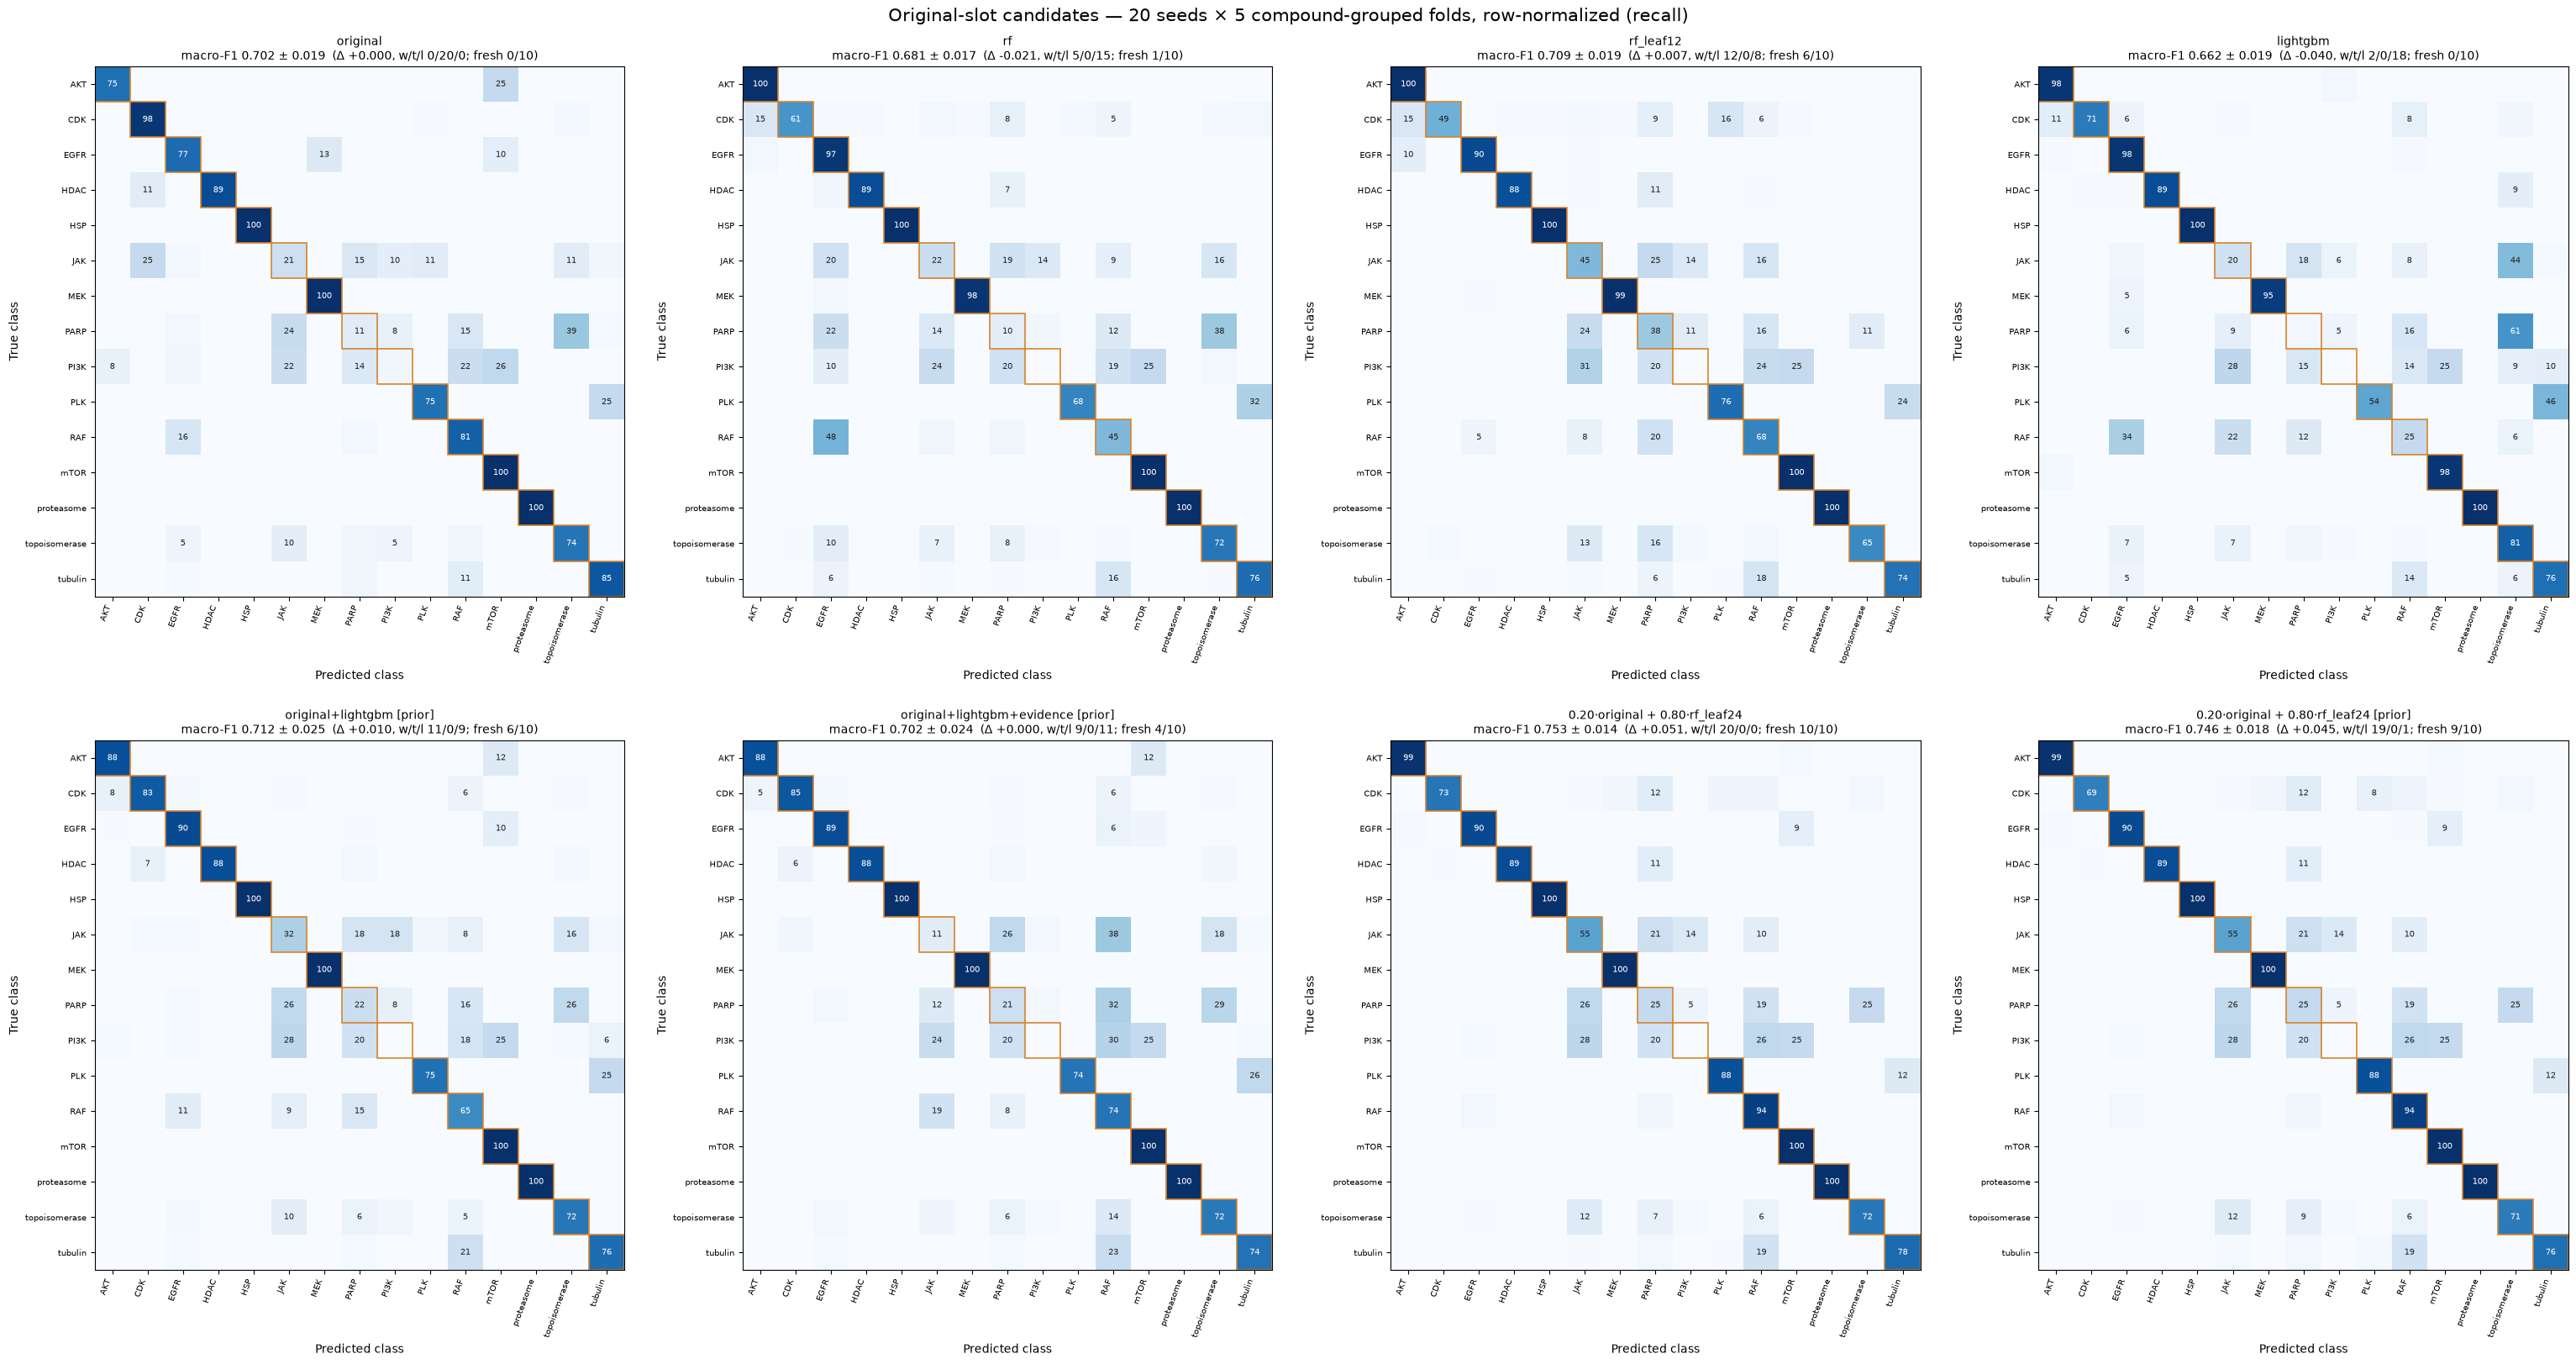

Saved: /home/aaleyasin/Projects/Omics-Hackathon2026/figures/original_model_alternatives_confusion.png


In [13]:
def short_label(label):
    return label.replace(" inhibitor", "").replace(" polymerization", "")


def draw_confusion(ax, matrix, labels, title):
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    for row in range(len(labels)):
        for column in range(len(labels)):
            value = matrix[row, column]
            if value >= 0.05:
                ax.text(
                    column, row, f"{value * 100:.0f}",
                    ha="center", va="center", fontsize=7,
                    color="white" if value > 0.55 else "#222222",
                )
        ax.add_patch(plt.Rectangle(
            (row - 0.5, row - 0.5), 1, 1,
            fill=False, edgecolor="#d9822b", linewidth=1.2,
        ))
    ax.set_xticks(range(len(labels)), labels, rotation=70, ha="right", fontsize=7)
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.grid(False)
    ax.set_title(title, fontsize=10)


short_classes = [short_label(label) for label in classes]
PANELS = ["original", "rf", RF_TUNED, "lightgbm",
          "original+lightgbm [prior]", "original+lightgbm+evidence [prior]", MIX, f"{MIX} [prior]"]
truth_pooled = fold_info["true"].to_numpy()

fig, axes = plt.subplots(2, 4, figsize=(31, 16))
for ax, name in zip(axes.flat, PANELS):
    predicted = class_array[candidates[name].to_numpy().argmax(axis=1)]
    counts = confusion_matrix(truth_pooled, predicted, labels=classes)
    normalized = counts / counts.sum(axis=1, keepdims=True)
    safe = (name.replace(" [prior]", "_prior").replace(" +", "_plus_").replace("+", "_plus_")
            .replace("·", "x").replace(" ", ""))
    pd.DataFrame(counts, index=classes, columns=classes).to_csv(RESULTS / f"confusion_{safe}_counts.csv")
    pd.DataFrame(normalized, index=classes, columns=classes).to_csv(RESULTS / f"confusion_{safe}_row_normalized.csv")
    row = summary.loc[name]
    draw_confusion(ax, normalized, short_classes,
                   f"{name}\nmacro-F1 {row['macro_f1']:.3f} ± {row['sd']:.3f}  (Δ {row['Δ vs original']:+.3f}, w/t/l {row['wins/ties/losses']}; fresh {row['fresh wins']})")
fig.suptitle("Original-slot candidates — 20 seeds × 5 compound-grouped folds, row-normalized (recall)", fontsize=15, y=1.0)
fig.tight_layout(h_pad=5)
figure_path = PLOTS / "original_model_alternatives_confusion.png"
fig.savefig(figure_path, dpi=120, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

### Where the candidates gain and lose: per-class recall minus the original's

Red means the candidate recovers more of that true class than the original does. Blue means it recovers less. Columns are sorted by the original's recall, hardest class first.

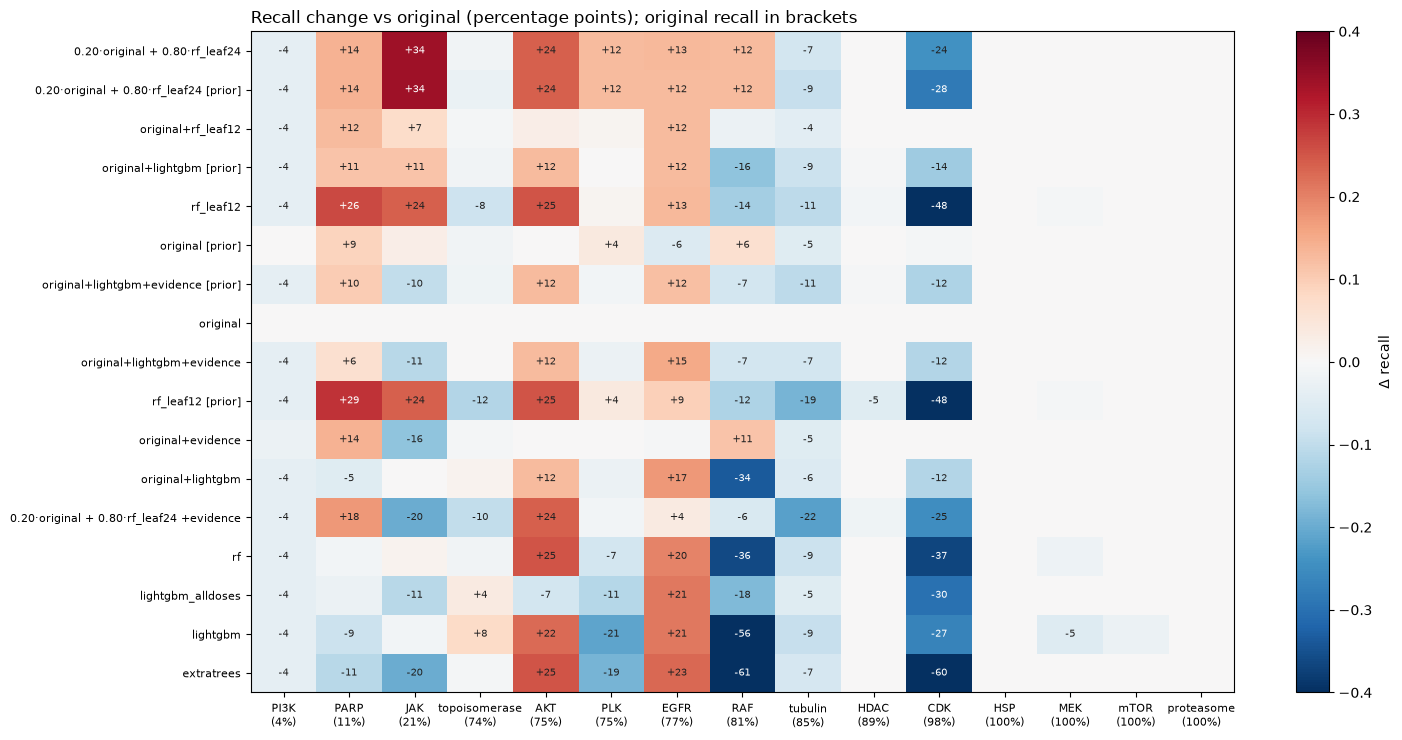

In [14]:
def recall(probability):
    predicted = class_array[probability.to_numpy().argmax(axis=1)]
    counts = confusion_matrix(truth_pooled, predicted, labels=classes)
    return pd.Series(np.diag(counts) / counts.sum(axis=1), index=short_classes)


recalls = pd.DataFrame({name: recall(p) for name, p in candidates.items()}).T
order = recalls.loc["original"].sort_values().index
delta = recalls[order].sub(recalls.loc["original", order], axis=1).loc[summary.index]
recalls.to_csv(RESULTS / "per_class_recall.csv")

fig, ax = plt.subplots(figsize=(15, 7.5))
image = ax.imshow(delta.to_numpy(), cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
for (i, j), value in np.ndenumerate(delta.to_numpy()):
    if abs(value) >= 0.03:
        ax.text(j, i, f"{value * 100:+.0f}", ha="center", va="center", fontsize=7, color="white" if abs(value) > 0.25 else "#222")
ax.set_xticks(range(len(order)), [f"{c}\n({recalls.loc['original', c] * 100:.0f}%)" for c in order], fontsize=8)
ax.set_yticks(range(len(delta)), delta.index, fontsize=8)
ax.set_title("Recall change vs original (percentage points); original recall in brackets", loc="left")
fig.colorbar(image, ax=ax, label="Δ recall")
fig.tight_layout()
fig.savefig(PLOTS / "original_model_alternatives_recall_delta.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Conclusion

**A tree model on its own does not replace the original.** On the same 20 × 5 splits the original scores macro-F1 0.702 ± 0.019. Default RF scores 0.681 (5/20 seed wins), LightGBM with the best_model parameters 0.662 (2/20), and ExtraTrees 0.618 (0/20). No LightGBM setting in the sweep came within 0.035 of the original. The best RF alone (`min_samples_leaf=12`) is a tie: +0.007, 12/20 wins, 6/10 on fresh seeds. The trees gain on AKT and EGFR but lose a lot on CDK, RAF and PLK.

**The best_model add-ons are within noise for this model:**

| add-on | change in macro-F1 | seed wins |
|---|---|---|
| LightGBM mix + prior correction | +0.010 | 11/20 |
| prior correction alone | +0.003 | — |
| PARP/RAF evidence terms | −0.005 to 0.000 | — |

The evidence terms do raise PARP and RAF recall, but they cost about the same on JAK.

**A weighted original + RF mix does improve the original confusion matrix.** The candidate is `0.20·original + 0.80·RF(min_samples_leaf=24)`, with leaf size and weight chosen on seeds 10–19:

- **Score:** macro-F1 0.753 ± 0.014 against 0.702, a gain of +0.051. It wins on 20/20 seeds and on 10/10 of the fresh seeds 20–29 (+0.043 there).
- **Robustness:** it is not a lucky cell. Every setting with leaf 8–24 and RF weight 0.7–0.8 gains +0.04 to +0.06 on both seed halves (§5 grid).
- **Gains in recall:** JAK +34, AKT +24, PARP +14, EGFR +13, PLK +12, RAF +12 percentage points.
- **Cost:** CDK recall drops from 98% to 73% and tubulin by 7 points.
- The two models make different mistakes, which is why mixing them helps even though RF alone only ties.

**Caveat for the blend.** With this mix in the original slot, the unchanged 25/75 blend drops from 0.744 to 0.732 (it wins only 4/20 seeds). The mix's gains overlap with what the trajectory model already recovers. The blend weight was tuned for the old original. So swapping the slot helps the original matrix, but helps the final blend only if the blend weight is retuned, which this notebook deliberately does not do.

Fresh seeds re-split the same 86 compounds, so they guard against a lucky setting but are not an independent test set. Leaf 24 sits at the edge of the grid, but the plateau makes the exact value unimportant.

## 9. Strategy 3: CDK-gated trajectory blend on the top-5 models

For every compound, separately for each base model:

- if the base model gives **CDK ≥ 0.25**, its own prediction is kept;
- otherwise the prediction comes from the **global 25/75 blend** (0.25 · base + 0.75 · trajectory, renormalized).

The base models are the original (as reference) and the current top 5 by macro-F1 from §6, single models included. The CV, the 20 seeds and the trajectory model are the same as above. Each Strategy 3 model is compared against its own no-trajectory version and against the walkthrough's blend (original + global 25/75 trajectory).

In [16]:
CDK = "CDK inhibitor"
CDK_GATE = 0.25


def strategy3(probability):
    """Keep the base model's prediction where it gives CDK >= 0.25; elsewhere use the global 25/75 trajectory blend."""
    keep = probability[CDK].to_numpy() >= CDK_GATE
    blend = blended(probability).loc[probability.index, classes]
    gated = np.where(keep[:, None], probability[classes].to_numpy(), blend.to_numpy())
    return pd.DataFrame(gated, index=probability.index, columns=classes), keep


TOP5 = list(summary.index[:5])                                   # current top 5 by macro-F1, single models included
STRAT3_MODELS = ["original"] + [name for name in TOP5 if name != "original"]
print("Strategy 3 base models:", *STRAT3_MODELS, sep="\n  ")

walkthrough_blend = blend_metrics["original"]["macro_f1"]      # original + global 25/75 trajectory (walkthrough blend)
cdk_rows = truth_pooled == CDK
strategy3_variants, strategy3_rows = {}, []
for name in STRAT3_MODELS:
    slot = candidates[name][classes]
    gated, keep = strategy3(slot)
    variants = {"no trajectory": slot, "global 25/75 blend": blended(slot).loc[slot.index, classes], "Strategy 3": gated}
    for variant, probability in variants.items():
        strategy3_variants[name, variant] = probability
        scores = per_seed_metrics(probability)["macro_f1"]
        d_own, _, wtl_own = record(scores, slot_metrics[name]["macro_f1"])
        d_wb, _, wtl_wb = record(scores, walkthrough_blend)
        fresh = scores.loc[FRESH_SEEDS] - walkthrough_blend.loc[FRESH_SEEDS]
        predicted = class_array[probability.to_numpy().argmax(axis=1)]
        strategy3_rows.append({
            "model": name, "variant": variant,
            "macro_f1": scores.mean(), "sd": scores.std(),
            "Δ vs own no-traj": d_own, "w/t/l vs own": wtl_own,
            "Δ vs walkthrough blend": d_wb, "w/t/l vs walkthrough blend": wtl_wb,
            "fresh Δ vs walkthrough blend": fresh.mean(), "fresh wins": f"{(fresh > 1e-9).sum()}/10",
            "CDK recall": np.mean(predicted[cdk_rows] == CDK),
            "gate kept base": keep.mean() if variant == "Strategy 3" else np.nan,
            "true CDK among kept": np.mean(truth_pooled[keep] == CDK) if variant == "Strategy 3" and keep.any() else np.nan,
        })

strategy3_summary = pd.DataFrame(strategy3_rows).set_index(["model", "variant"])
strategy3_summary.to_csv(RESULTS / "strategy3_top5_summary.csv")
print(f"walkthrough blend (original + global 25/75): macro-F1 {walkthrough_blend.mean():.3f} ± {walkthrough_blend.std():.3f}")
display(strategy3_summary.style
        .format({c: "{:.3f}" for c in strategy3_summary.columns if strategy3_summary[c].dtype.kind == "f"}, na_rep="")
        .background_gradient(subset=["Δ vs walkthrough blend", "fresh Δ vs walkthrough blend"], cmap="RdBu", vmin=-0.05, vmax=0.05))

Strategy 3 base models:
  original
  0.20·original + 0.80·rf_leaf24
  0.20·original + 0.80·rf_leaf24 [prior]
  original+rf_leaf12
  original+lightgbm [prior]
  rf_leaf12
walkthrough blend (original + global 25/75): macro-F1 0.744 ± 0.020


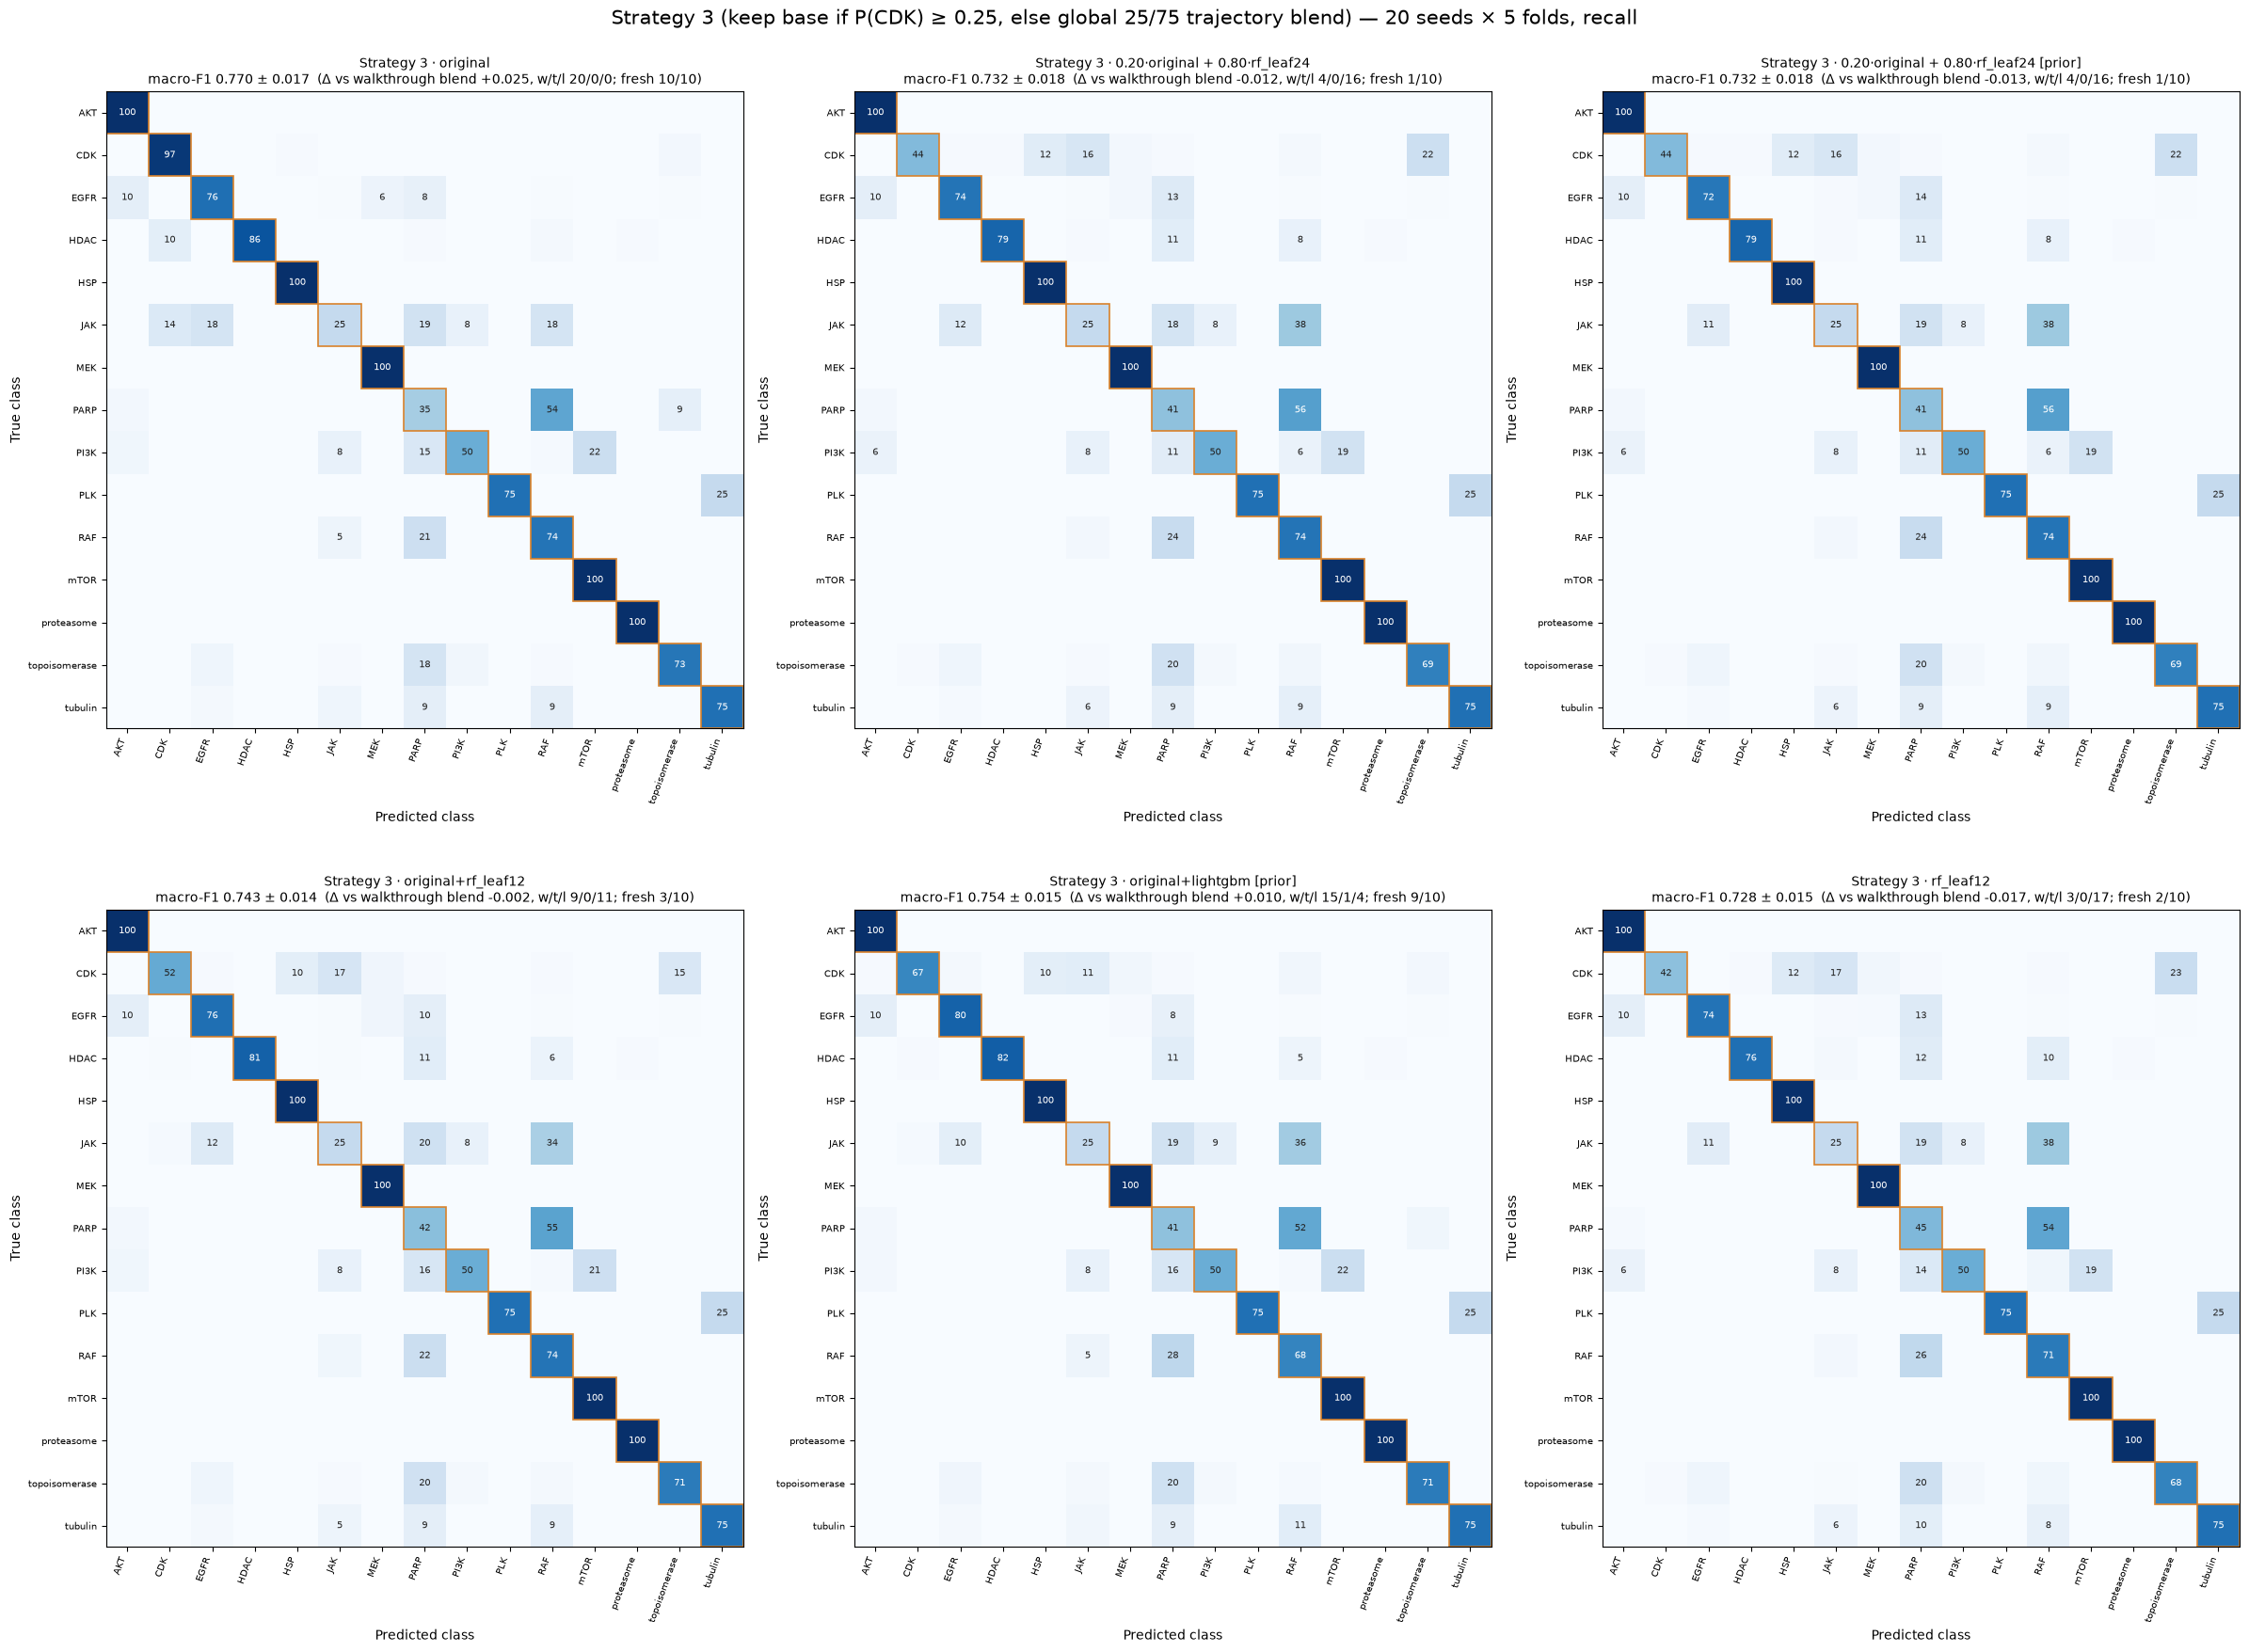

Saved: /home/aaleyasin/Projects/Omics-Hackathon2026/figures/original_model_alternatives_strategy3_confusion.png


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(24, 17.5))
for ax, name in zip(axes.flat, STRAT3_MODELS):
    probability = strategy3_variants[name, "Strategy 3"]
    predicted = class_array[probability.to_numpy().argmax(axis=1)]
    counts = confusion_matrix(truth_pooled, predicted, labels=classes)
    normalized = counts / counts.sum(axis=1, keepdims=True)
    safe = (name.replace(" [prior]", "_prior").replace(" +", "_plus_").replace("+", "_plus_")
            .replace("·", "x").replace(" ", ""))
    pd.DataFrame(counts, index=classes, columns=classes).to_csv(RESULTS / f"confusion_strategy3_{safe}_counts.csv")
    pd.DataFrame(normalized, index=classes, columns=classes).to_csv(RESULTS / f"confusion_strategy3_{safe}_row_normalized.csv")
    row = strategy3_summary.loc[(name, "Strategy 3")]
    draw_confusion(ax, normalized, short_classes,
                   f"Strategy 3 · {name}\nmacro-F1 {row['macro_f1']:.3f} ± {row['sd']:.3f}  "
                   f"(Δ vs walkthrough blend {row['Δ vs walkthrough blend']:+.3f}, w/t/l {row['w/t/l vs walkthrough blend']}; "
                   f"fresh {row['fresh wins']})")
for ax in axes.flat[len(STRAT3_MODELS):]:
    ax.axis("off")
fig.suptitle(f"Strategy 3 (keep base if P(CDK) ≥ {CDK_GATE}, else global 25/75 trajectory blend) — 20 seeds × 5 folds, recall",
             fontsize=15, y=1.0)
fig.tight_layout(h_pad=4)
figure_path = PLOTS / "original_model_alternatives_strategy3_confusion.png"
fig.savefig(figure_path, dpi=120, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

In [18]:
strategy3_recall = pd.DataFrame({key: recall(p) for key, p in strategy3_variants.items()}).T
strategy3_recall.index.names = ["model", "variant"]
strategy3_recall = strategy3_recall[recalls.loc["original"].sort_values().index]   # hardest class first, as in §7
strategy3_recall.to_csv(RESULTS / "strategy3_per_class_recall.csv")
display(strategy3_recall.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1))

## 10. Follow-ups to Strategy 3

Strategy 3 works on the original (0.770, 20/20 seeds against the walkthrough blend) but does nothing on the RF mixes. Their probabilities are flat, so the CDK ≥ 0.25 gate almost never fires, and the 75% trajectory weight erases their JAK/RAF/PLK/EGFR gains. Three checks follow. All tuning uses seeds 10–19 only, and seeds 20–29 are reported as fresh seeds.

1. Is the 0.25 threshold stable?
2. Gate on the original's CDK probability, and tune the trajectory weight per base model.
3. Gate more than one class: choose greedily which model to trust for which class.

In [19]:
from itertools import product

order_index = fold_info.index
seed_of = order_index.get_level_values("seed").to_numpy()
LABELS = np.arange(len(classes))
truth_idx = pd.Index(classes).get_indexer(truth_pooled)
P_traj = base["trajectory"].loc[order_index, classes].to_numpy()
arr = lambda name: candidates[name].loc[order_index, classes].to_numpy()


def macro_f1_by_seed(pred_idx, seeds=SEEDS):
    return pd.Series({s: f1_score(truth_idx[seed_of == s], pred_idx[seed_of == s], labels=LABELS,
                                  average="macro", zero_division=0) for s in seeds})


def blend_arr(P, w=TRAJECTORY_WEIGHT):
    B = (1 - w) * P + w * P_traj
    return B / B.sum(axis=1, keepdims=True)


def gate(gate_P, keep_P, else_P, cls=CDK, t=CDK_GATE):
    """Strategy 3, generalised: where gate_P[cls] >= t use keep_P's call, otherwise else_P's call."""
    keep = gate_P[:, classes.index(cls)] >= t
    return np.where(keep, keep_P.argmax(1), else_P.argmax(1)), keep


P_orig = arr("original")
WB = macro_f1_by_seed(blend_arr(P_orig).argmax(1))               # walkthrough blend = reference


def versus_wb(scores):
    tune, fresh = scores.loc[TUNE_SEEDS] - WB.loc[TUNE_SEEDS], scores.loc[FRESH_SEEDS] - WB.loc[FRESH_SEEDS]
    return {"macro_f1": scores.mean(), "sd": scores.std(),
            "tune Δ vs WB": tune.mean(), "tune wins": f"{(tune > 1e-9).sum()}/10",
            "fresh Δ vs WB": fresh.mean(), "fresh wins": f"{(fresh > 1e-9).sum()}/10"}


print(f"walkthrough blend: {WB.mean():.3f}  (should be 0.744)")
F = lambda df: df.style.format({c: "{:.3f}" for c in df.columns if df[c].dtype.kind == "f"}, na_rep="")

rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60]:
    pred, keep = gate(P_orig, P_orig, blend_arr(P_orig), CDK, t)
    rows.append({"CDK threshold": t, "gate fires": keep.mean(),
                 "true CDK among kept": (truth_pooled[keep] == CDK).mean() if keep.any() else np.nan,
                 **versus_wb(macro_f1_by_seed(pred))})
threshold_sweep = pd.DataFrame(rows).set_index("CDK threshold")
threshold_sweep.to_csv(RESULTS / "strategy3_threshold_sweep.csv")
display(F(threshold_sweep))

walkthrough blend: 0.744  (should be 0.744)


,gate fires,true CDK among kept,macro_f1,sd,tune Δ vs WB,tune wins,fresh Δ vs WB,fresh wins
CDK threshold,,,,,,,,
0.100000,0.136,0.509,0.766,0.017,0.019,8/10,0.024,10/10
0.150000,0.106,0.654,0.769,0.018,0.024,10/10,0.025,10/10
0.200000,0.104,0.665,0.769,0.018,0.024,10/10,0.025,10/10
0.250000,0.096,0.709,0.770,0.017,0.024,10/10,0.026,10/10
0.300000,0.065,0.884,0.762,0.018,0.017,10/10,0.019,9/10
0.350000,0.038,0.954,0.746,0.018,0.001,1/10,0.003,2/10
0.400000,0.034,0.983,0.746,0.018,-0.000,0/10,0.003,2/10
0.500000,0.033,1.000,0.746,0.018,0.000,0/10,0.003,2/10
0.600000,0.026,1.000,0.746,0.018,0.000,0/10,0.003,2/10


In [20]:
TRAJ_WEIGHTS = [0.25, 0.4, 0.5, 0.6, 0.75, 0.9]
rows, tuned_scores = [], {}
for name in STRAT3_MODELS:
    P = arr(name)
    for gate_source, G in [("self", P), ("original", P_orig)]:
        by_w = {w: macro_f1_by_seed(gate(G, G, blend_arr(P, w))[0]) for w in TRAJ_WEIGHTS}
        w_star = max(TRAJ_WEIGHTS, key=lambda w: by_w[w].loc[TUNE_SEEDS].mean())   # chosen on seeds 10-19
        tuned_scores[name, gate_source] = (w_star, by_w[w_star])
        rows.append({"base model": name, "gate + keep from": gate_source, "w_traj (chosen on 10-19)": w_star,
                     "macro_f1 at w=0.75": by_w[0.75].mean(), **versus_wb(by_w[w_star])})
gate_weight_table = pd.DataFrame(rows).set_index(["base model", "gate + keep from"])
gate_weight_table.to_csv(RESULTS / "strategy3_gate_source_and_weight.csv")
display(F(gate_weight_table).background_gradient(subset=["fresh Δ vs WB"], cmap="RdBu", vmin=-0.05, vmax=0.05))

In [21]:
SOURCES = {"original": P_orig, "mix": arr(MIX)}             # models allowed to override the blend
FALLBACK = blend_arr(P_orig, 0.75)                           # swap in the best (base, w) from cell 3 if it wins on fresh seeds
THRESHOLDS = [0.25, 0.35, 0.5]
MAX_RULES = 4


def apply_rules(rules, fallback=FALLBACK):
    """Rules (source, class, t) are applied in order: the first rule whose source gives class >= t
    takes that source's call; compounds no rule claims get the fallback blend's call."""
    pred, taken = fallback.argmax(1).copy(), np.zeros(len(fallback), bool)
    for source, cls, t in rules:
        fire = ~taken & (SOURCES[source][:, classes.index(cls)] >= t)
        pred[fire] = SOURCES[source][fire].argmax(1)
        taken |= fire
    return pred


tune_score = lambda rules: macro_f1_by_seed(apply_rules(rules), TUNE_SEEDS).mean()
rules, current = [], tune_score([])
print(f"start (fallback only): tune macro-F1 {current:.3f}")
for step in range(MAX_RULES):
    options = [(s, c, t) for s, c, t in product(SOURCES, classes, THRESHOLDS) if all(c != r[1] for r in rules)]
    scored = {o: tune_score(rules + [o]) for o in options}
    best = max(scored, key=scored.get)
    if scored[best] <= current + 0.002:                      # stop when a rule adds < 0.002 on the tuning seeds
        break
    rules.append(best); current = scored[best]
    print(f"step {step + 1}: + if {best[0]} P({short_label(best[1])}) >= {best[2]} keep {best[0]}  -> tune macro-F1 {current:.3f}")

strategy_options = {
    "walkthrough blend": blend_arr(P_orig).argmax(1),
    "Strategy 3 · original": gate(P_orig, P_orig, blend_arr(P_orig))[0],
    "greedy multi-class gates": apply_rules(rules),
}
strategy_table = pd.DataFrame({k: versus_wb(macro_f1_by_seed(p)) for k, p in strategy_options.items()}).T
strategy_table["rules"] = ["", f"original P(CDK) >= {CDK_GATE}",
                           "; ".join(f"{s} P({short_label(c)})>={t}" for s, c, t in rules)]
strategy_table.to_csv(RESULTS / "strategy3_greedy_rules.csv")
display(F(strategy_table))

start (fallback only): tune macro-F1 0.747
step 1: + if original P(CDK) >= 0.25 keep original  -> tune macro-F1 0.771
step 2: + if mix P(PLK) >= 0.25 keep mix  -> tune macro-F1 0.780
step 3: + if original P(tubulin) >= 0.25 keep original  -> tune macro-F1 0.786


,macro_f1,sd,tune Δ vs WB,tune wins,fresh Δ vs WB,fresh wins,rules
walkthrough blend,0.744499,0.019731,0.000000,0/10,0.000000,0/10,
Strategy 3 · original,0.769523,0.016655,0.023812,10/10,0.026236,10/10,original P(CDK) >= 0.25
greedy multi-class gates,0.781943,0.020820,0.039251,10/10,0.035636,10/10,original P(CDK)>=0.25; mix P(PLK)>=0.25; original P(tubulin)>=0.25


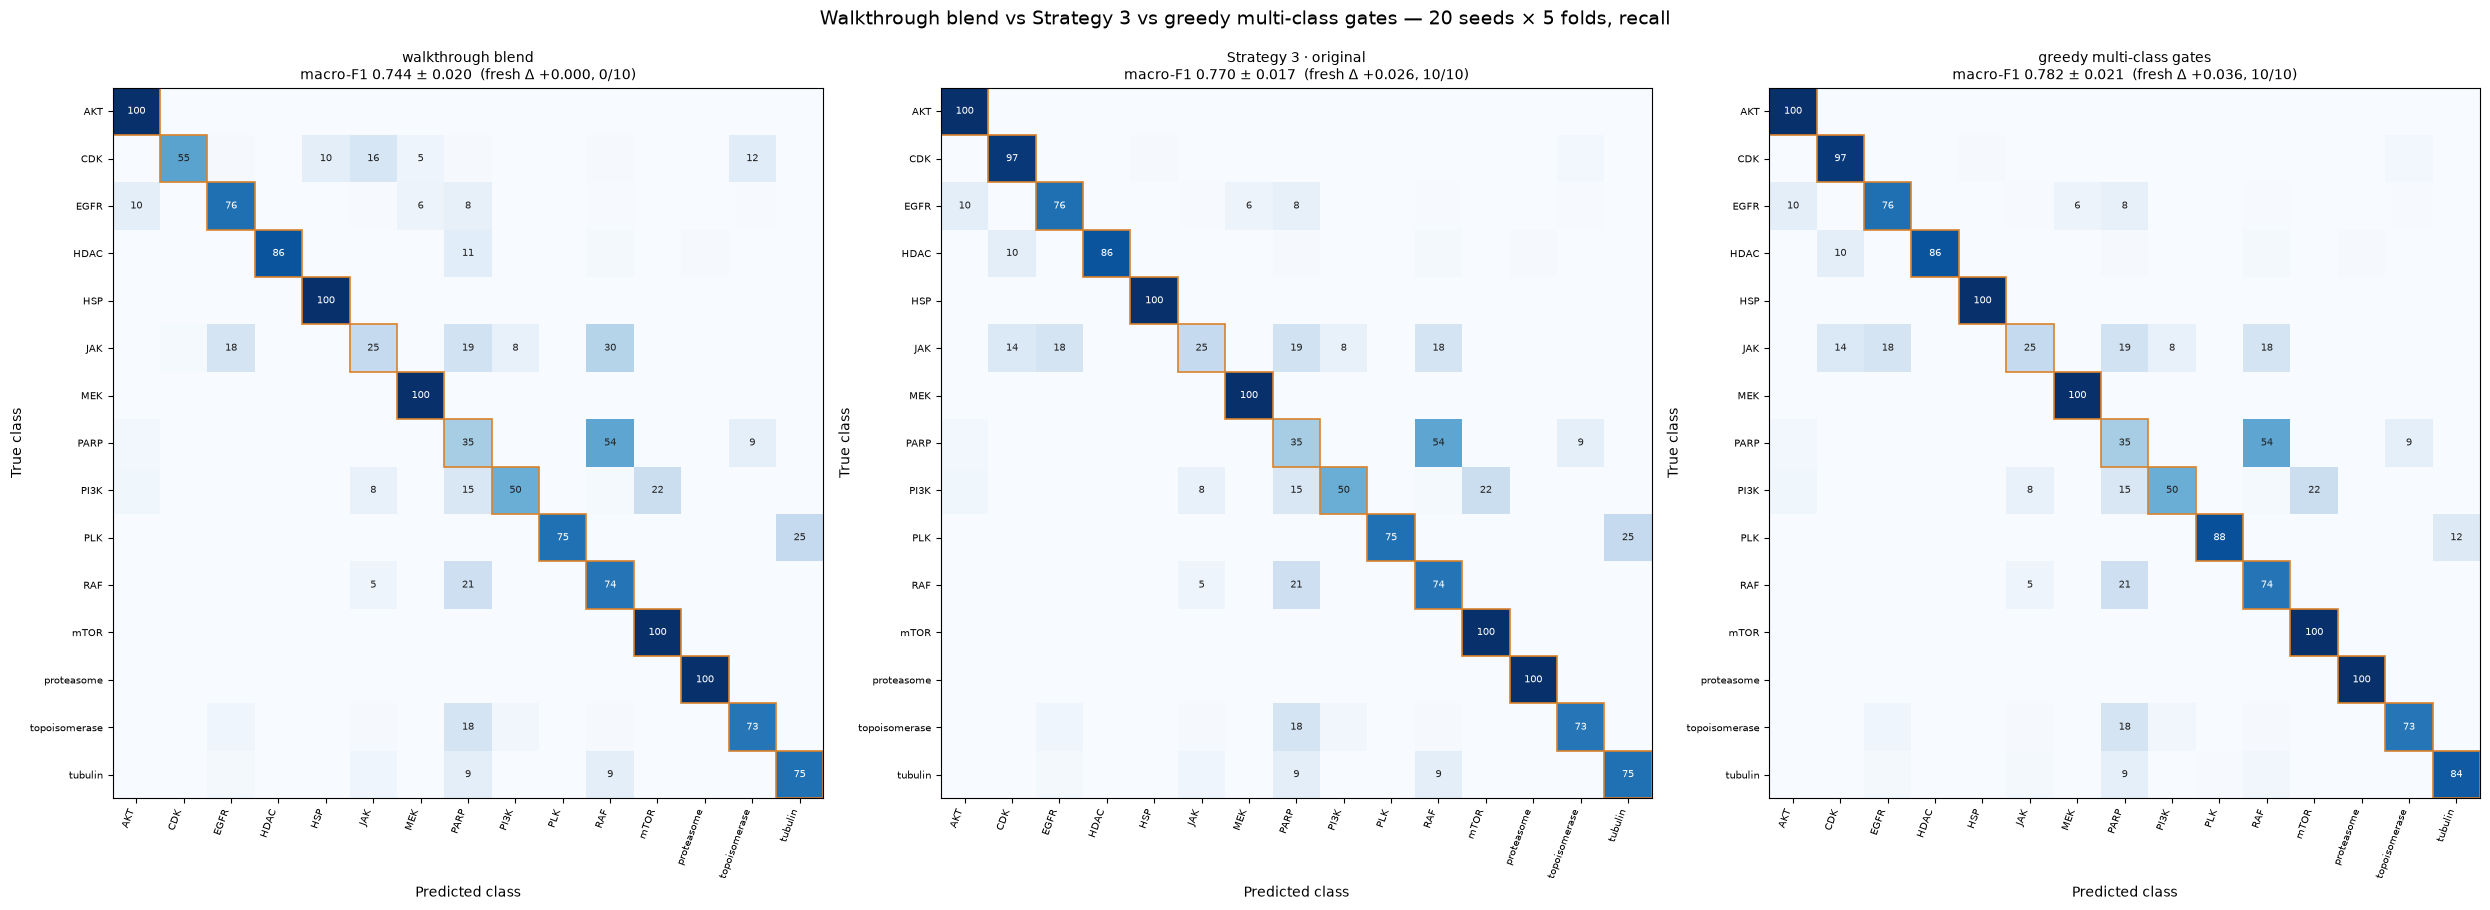

,PI3K,PARP,JAK,topoisomerase,AKT,PLK,EGFR,RAF,tubulin,HDAC,CDK,HSP,MEK,mTOR,proteasome
walkthrough blend,0.50,0.35,0.25,0.73,1.00,0.75,0.76,0.74,0.75,0.86,0.55,1.00,1.00,1.00,1.00
Strategy 3 · original,0.50,0.35,0.25,0.73,1.00,0.75,0.76,0.74,0.75,0.86,0.97,1.00,1.00,1.00,1.00
greedy multi-class gates,0.50,0.35,0.25,0.73,1.00,0.88,0.76,0.74,0.84,0.86,0.97,1.00,1.00,1.00,1.00


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(25, 8.8))
strategy_recall = {}
for ax, (name, pred) in zip(axes, strategy_options.items()):
    counts = confusion_matrix(truth_idx, pred, labels=LABELS)
    normalized = counts / counts.sum(axis=1, keepdims=True)
    strategy_recall[name] = pd.Series(np.diag(normalized), index=short_classes)
    row = strategy_table.loc[name]
    draw_confusion(ax, normalized, short_classes,
                   f"{name}\nmacro-F1 {row['macro_f1']:.3f} ± {row['sd']:.3f}  (fresh Δ {row['fresh Δ vs WB']:+.3f}, {row['fresh wins']})")
fig.suptitle("Walkthrough blend vs Strategy 3 vs greedy multi-class gates — 20 seeds × 5 folds, recall", fontsize=14, y=1.0)
fig.tight_layout()
fig.savefig(PLOTS / "original_model_alternatives_strategy3_followups.png", dpi=120, bbox_inches="tight")
plt.show()
display(pd.DataFrame(strategy_recall).T[strategy3_recall.columns].style.format("{:.2f}")
        .background_gradient(cmap="Blues", vmin=0, vmax=1))